# Pérdidas y ganancias de portafolios correlacionados

Se construyen tres portafolios con AAPL, MSFT y NVDA, cuyos precios a un año se simulan con correlación mediante Cholesky, y se analiza la **ganancia o pérdida** de cada escenario:

$$\text{P\&L} = V_T - V_0$$

| Portafolio | Pesos $w$ (AAPL, MSFT, NVDA) |
|---|---|
| P1 | [1, 0, 0] |
| P2 | [0.33, 0.33, 0.34] |
| P3 | [0.2, 0.2, 0.6] |

**Inversión inicial:** $V_0 = 100{,}000$ USD

**Contenido:**
1. Simulación de precios correlacionados, con el rendimiento del último año como tendencia.
2. Construcción de los portafolios y su valor final.
3. Distribución de pérdidas y ganancias.

---

### Librerías

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

---

# Parte 1. Simulación de precios correlacionados

Cada precio se simula a un año con:

$$S_i(T) = S_i(0)\, e^{\left(r_i - \frac{1}{2}\Sigma_{ii}\right)T + \sqrt{T}\, Z_i}, \qquad Z = L\,\varepsilon$$

- $r_i$: rendimiento anual de la acción, estimado con el último año de datos.
- $\Sigma_{ii}$: varianza anual de la acción (diagonal de la matriz de covarianzas).
- $L$: factor de Cholesky de $\Sigma$, que convierte choques independientes $\varepsilon$ en choques correlacionados $Z$.

### Descarga de AAPL, MSFT y NVDA (últimos 3 años)

In [2]:
tickers_tec = ["AAPL", "MSFT", "NVDA"]

data_tec = yf.download(tickers_tec, start="2023-11-01", end="2026-11-01",
                       auto_adjust=True, progress=False)

precios_tec = data_tec["Close"][tickers_tec].dropna()
print(f"Observaciones: {len(precios_tec)}")
precios_tec.tail()

Observaciones: 752


Ticker,AAPL,MSFT,NVDA
Date,,,
2026-10-26,343.910004,532.599976,216.000000
2026-10-27,347.100006,531.330017,217.940002
2026-10-28,343.829987,531.010010,215.380005
2026-10-29,348.910004,530.140015,213.660004
2026-10-30,344.630005,521.909973,204.639999


### Rendimientos logarítmicos, correlación y covarianza anualizada

In [3]:
log_ret_tec = np.log(precios_tec / precios_tec.shift(1)).dropna()

correlacion = log_ret_tec.corr()
covarianza  = log_ret_tec.cov() * 252

print("Correlación:")
print(correlacion.round(4))
print("\nCovarianza anualizada:")
print(covarianza.round(4))

Correlación:
Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3343  0.2844
MSFT    0.3343  1.0000  0.4219
NVDA    0.2844  0.4219  1.0000

Covarianza anualizada:
Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    0.0712  0.0231  0.0353
MSFT    0.0231  0.0672  0.0509
NVDA    0.0353  0.0509  0.2168


### Rendimiento esperado de cada acción (último año)

La tendencia de cada acción es su rendimiento logarítmico anual, estimado con los últimos 252 días hábiles:

$$r_i = 252 \cdot \overline{\ln\left(\frac{S_t}{S_{t-1}}\right)}$$

In [4]:
log_ret_1a = log_ret_tec.iloc[-252:]
r_tec = log_ret_1a.mean() * 252

pd.DataFrame({"r (log anual)": r_tec,
              "Rend. simple (%)": (np.exp(r_tec) - 1) * 100}).round(4)

,r (log anual),Rend. simple (%)
Ticker,,
AAPL,0.2488,28.2548
MSFT,-0.0287,-2.8337
NVDA,-0.0093,-0.9224


### Cholesky y choques correlacionados Z = L ε

In [5]:
M = 10_000
T = 1
Sigma = covarianza.values
L = np.linalg.cholesky(Sigma)

np.random.seed(42)
epsilon = np.random.normal(0, 1, [M, len(tickers_tec)])

Z_tec = epsilon @ L.T

print(f"¿L · Lᵀ reconstruye Σ? {np.allclose(L @ L.T, Sigma)}")
print("\nCorrelación simulada:")
print(pd.DataFrame(Z_tec, columns=tickers_tec).corr().round(3))

¿L · Lᵀ reconstruye Σ? True

Correlación simulada:
       AAPL   MSFT   NVDA
AAPL  1.000  0.328  0.268
MSFT  0.328  1.000  0.421
NVDA  0.268  0.421  1.000


### Precios a un año

El término $-\frac{1}{2}\Sigma_{ii}$ corrige la convexidad de la exponencial, de modo que el precio esperado crece exactamente a la tasa $r_i$:

$$E[S_i(T)] = S_i(0)\, e^{r_i T}$$

In [6]:
S0_tec = precios_tec.iloc[-1]
drift = (r_tec.values - 0.5 * np.diag(Sigma)) * T

ST_tec = S0_tec.values * np.exp(drift + np.sqrt(T) * Z_tec)
ST_tec = pd.DataFrame(ST_tec, columns=tickers_tec)

pd.DataFrame({"S0": S0_tec,
              "Media S_T simulada": ST_tec.mean(),
              "E[S_T] teórico": S0_tec.values * np.exp(r_tec.values * T)}).round(2)

,S0,Media S_T simulada,E[S_T] teórico
AAPL,344.63,441.44,442.00
MSFT,521.91,507.10,507.12
NVDA,204.64,202.40,202.75


---

# Parte 2. Construcción de los portafolios

Cada activo recibe la fracción $w_i$ de la inversión, así que se compran $N_i = \dfrac{w_i V_0}{S_i(0)}$ acciones. El valor final es:

$$V_T = \sum_i N_i\, S_i(T) = V_0 \sum_i w_i \frac{S_i(T)}{S_i(0)}$$

Es decir, cada peso multiplica el rendimiento bruto de su acción. Por ejemplo, en P1 todo se invierte en AAPL y $V_T = 100{,}000 \cdot \dfrac{S_{AAPL}(T)}{S_{AAPL}(0)}$.

### Valor final de cada portafolio

In [7]:
V0 = 100_000

portafolios_tec = {
    "P1": np.array([1, 0, 0]),
    "P2": np.array([0.33, 0.33, 0.34]),
    "P3": np.array([0.2, 0.2, 0.6]),
}

rend_bruto = ST_tec.values / S0_tec.values

VT_tec = pd.DataFrame({nombre: V0 * rend_bruto @ w
                       for nombre, w in portafolios_tec.items()})
VT_tec.describe().round(2)

,P1,P2,P3
count,10000.00,10000.00,10000.00
mean,128091.32,107961.20,104393.50
std,34908.33,27232.88,33976.89
min,44233.83,43929.19,31874.74
25%,102968.02,88258.90,80471.67
50%,123592.60,104359.07,98309.62
75%,148170.48,123226.63,122202.23
max,408914.03,298820.36,408499.26


### Valor final promedio de cada portafolio

Se compara el promedio simulado con el valor teórico:

$$E[V_T] = V_0 \sum_i w_i\, e^{r_i T}$$

El promedio de cada portafolio depende solo de los rendimientos $r_i$ y de los pesos, no de la volatilidad.

In [8]:
VT_promedio = pd.DataFrame({
    "Pesos": {k: str(w) for k, w in portafolios_tec.items()},
    "V_T promedio simulado": VT_tec.mean(),
    "E[V_T] teórico": {k: V0 * np.sum(w * np.exp(r_tec.values * T))
                       for k, w in portafolios_tec.items()},
})
VT_promedio.round(2)

,Pesos,V_T promedio simulado,E[V_T] teórico
P1,[1 0 0],128091.32,128254.75
P2,[0.33 0.33 0.34],107961.20,108075.33
P3,[0.2 0.2 0.6],104393.50,104530.77


---

# Parte 3. Pérdidas y ganancias

$$\text{P\&L} = V_T - V_0$$

- **P&L > 0:** el portafolio ganó dinero.
- **P&L < 0:** el portafolio perdió dinero.

### Pérdidas y ganancias de cada escenario

In [9]:
PnL = VT_tec - V0
PnL.head()

,P1,P2,P3
0,41309.695769,19260.374830,20170.350766
1,85821.963647,27034.595795,14416.361065
2,88628.489337,39813.558014,24923.329664
3,43048.855520,1052.425385,-9991.249900
4,32023.852228,-25411.257931,-41842.568665


### Resumen de pérdidas y ganancias

- **Media:** ganancia promedio esperada.
- **P(pérdida):** porcentaje de escenarios en los que se pierde dinero.
- **Percentil 5%:** el 5% de los peores escenarios pierde al menos esta cantidad.
- **Pérdida promedio:** cuánto se pierde en promedio en los escenarios con pérdida.

In [10]:
resumen_pnl = pd.DataFrame({
    "Media": PnL.mean(),
    "Desv. est.": PnL.std(),
    "Mínimo": PnL.min(),
    "Máximo": PnL.max(),
    "P(pérdida) (%)": (PnL < 0).mean() * 100,
    "Percentil 5%": PnL.quantile(0.05),
    "Pérdida promedio": PnL[PnL < 0].mean(),
})
resumen_pnl.round(2)

,Media,Desv. est.,Mínimo,Máximo,P(pérdida) (%),Percentil 5%,Pérdida promedio
P1,28091.32,34908.33,-55766.17,308914.03,21.56,-20258.92,-13406.85
P2,7961.20,27232.88,-56070.81,198820.36,43.29,-29159.32,-15392.03
P3,4393.50,33976.89,-68125.26,308499.26,52.62,-38606.36,-20010.50


### Histogramas de pérdidas y ganancias

Las barras rojas son escenarios con pérdida y las verdes con ganancia. La línea negra marca el punto de equilibrio (P&L = 0), la naranja el percentil 5% y la dorada la media.

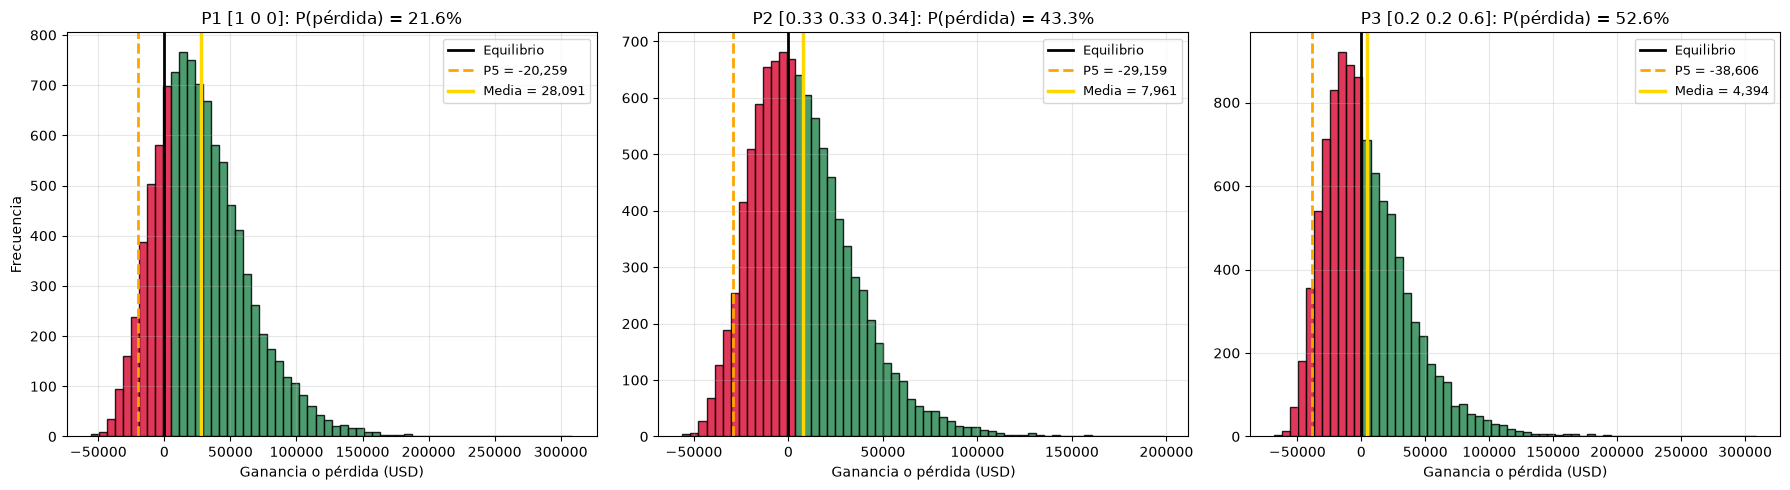

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, portafolio in zip(axes, PnL.columns):
    datos = PnL[portafolio]
    n_barras, bins, barras = ax.hist(datos, bins=60, edgecolor="black", alpha=0.85)

    for barra, borde_izq in zip(barras, bins[:-1]):
        barra.set_facecolor("crimson" if borde_izq < 0 else "seagreen")

    ax.axvline(0, color="black", lw=2, label="Equilibrio")
    ax.axvline(datos.quantile(0.05), color="orange", ls="--", lw=2,
               label=f"P5 = {datos.quantile(0.05):,.0f}")
    ax.axvline(datos.mean(), color="gold", lw=2.5, label=f"Media = {datos.mean():,.0f}")

    ax.set_title(f"{portafolio} {portafolios_tec[portafolio]}: P(pérdida) = {(datos < 0).mean()*100:.1f}%")
    ax.set_xlabel("Ganancia o pérdida (USD)")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Comparación de los tres portafolios en una sola gráfica

Se grafican todos los escenarios, desde la peor pérdida hasta la mayor ganancia, sin recortar ninguna cola.

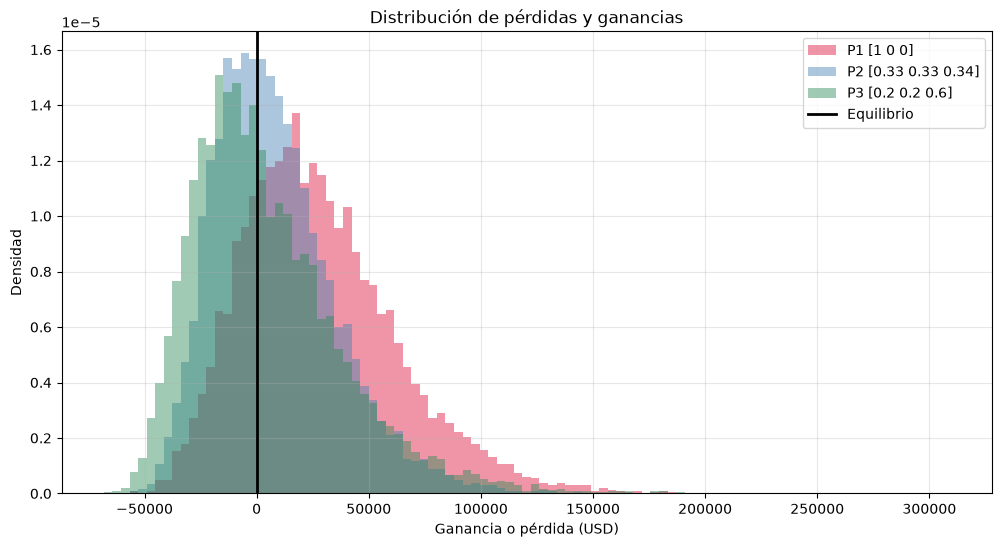

In [12]:
plt.figure(figsize=(12, 6))
colores_pnl = ["crimson", "steelblue", "seagreen"]
bins = np.linspace(PnL.min().min(), PnL.max().max(), 100)

for portafolio, color in zip(PnL.columns, colores_pnl):
    plt.hist(PnL[portafolio], bins=bins, alpha=0.45, density=True,
             color=color, label=f"{portafolio} {portafolios_tec[portafolio]}")

plt.axvline(0, color="black", lw=2, label="Equilibrio")
plt.xlabel("Ganancia o pérdida (USD)")
plt.ylabel("Densidad")
plt.title("Distribución de pérdidas y ganancias")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Zoom en las pérdidas

Solo los escenarios con pérdida, para comparar qué tan profundas pueden ser en cada portafolio.

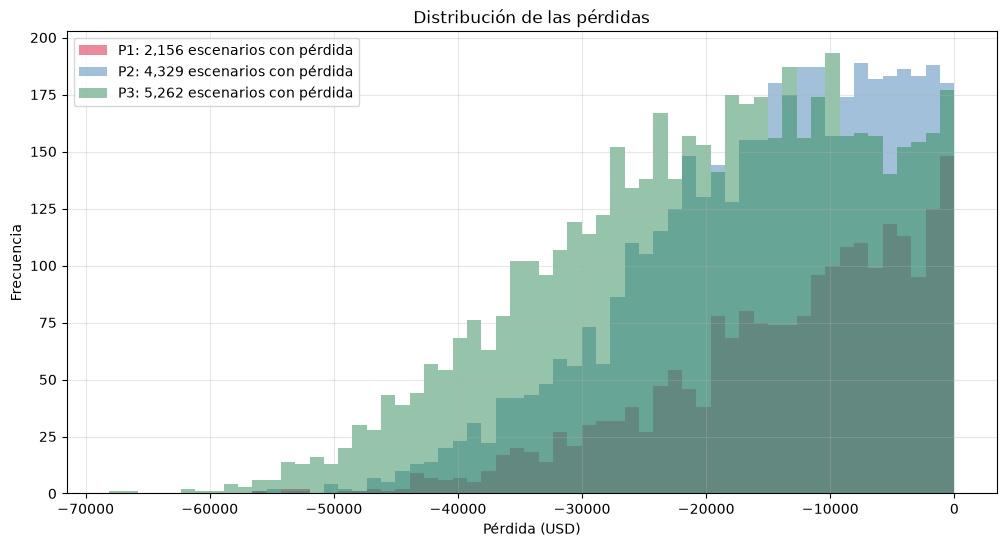

In [13]:
plt.figure(figsize=(12, 6))
bins = np.linspace(PnL.min().min(), 0, 60)

for portafolio, color in zip(PnL.columns, colores_pnl):
    perdidas = PnL[portafolio][PnL[portafolio] < 0]
    plt.hist(perdidas, bins=bins, alpha=0.5, color=color,
             label=f"{portafolio}: {len(perdidas):,} escenarios con pérdida")

plt.xlabel("Pérdida (USD)")
plt.ylabel("Frecuencia")
plt.title("Distribución de las pérdidas")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

---

# Conclusiones

**1. El valor final promedio depende solo de los rendimientos y los pesos.**
Gracias al término $-\frac{1}{2}\Sigma_{ii}$, cada acción crece en promedio exactamente a su tasa $r_i$, sin importar qué tan volátil sea. Por eso $E[V_T] = V_0 \sum_i w_i e^{r_i T}$: el portafolio con el promedio más alto es el que pone más peso en la acción que mejor rindió el último año. La tabla de V_T promedio confirma que la simulación coincide con este valor teórico.

**2. P1 tiene el valor final promedio más alto porque está todo en AAPL.**
AAPL fue la acción con mejor rendimiento del último año, y P1 la tiene al 100%. Conforme el peso se mueve hacia MSFT y NVDA, que rindieron menos en ese periodo, el promedio baja: P2 queda en medio y P3, con 60% en NVDA, es el de menor V_T promedio.

**3. El riesgo no sigue el mismo orden que el rendimiento.**
La volatilidad no cambia el promedio, pero sí el ancho de la distribución. P3, con 60% en NVDA (la acción más volátil), tiene el histograma más ancho, la mayor desviación estándar y la cola de pérdidas más profunda. P2 reparte el peso entre las tres acciones y aprovecha que no se mueven igual, lo que reduce su dispersión.

**4. La diversificación dentro del mismo sector tiene un límite.**
Las tres son tecnológicas con correlaciones positivas, así que tienden a caer juntas. Combinarlas reduce el riesgo, pero menos de lo que lo haría mezclar activos de sectores distintos o con correlación baja.

**5. El rendimiento histórico de un año es un supuesto fuerte.**
Usar el rendimiento del último año como tendencia supone que el próximo año se va a repetir. Un año muy bueno de AAPL hace que P1 se vea como la mejor opción, pero ese resultado depende por completo del periodo elegido; con otra ventana de datos el orden podría invertirse.

**6. El P&L muestra lo que el valor final no deja ver.**
Graficar $V_T - V_0$ pone el punto de equilibrio en cero y separa con claridad los escenarios de pérdida (rojo) de los de ganancia (verde). El percentil 5% traduce el riesgo a dinero: en el 5% de los peores escenarios (uno de cada veinte años) se pierde al menos esa cantidad de los 100,000 invertidos. Esta cifra es la base del **Valor en Riesgo (VaR)** al 95%.